# LSTM contra outros modelos explicáveis por SHAP e LIME

Este notebook complementa a E5 e a E6 (ADR 0018). A pergunta é: **o resultado vem da LSTM, ou outros modelos explicáveis fariam o mesmo?** Foram comparados quatro modelos, nos mesmos dados, dobras e métricas da E5/E6:

| Modelo | Família | Explicação SHAP | LIME |
|---|---|---|---|
| LightGBM | árvores, supervisionado | TreeSHAP exato | o mesmo da E6 |
| Isolation Forest | árvores, não supervisionado | TreeSHAP exato | o mesmo da E6 |
| Regressão logística L1 | linear, supervisionado | SHAP linear exato | o mesmo da E6 |
| TCN classificadora | rede convolucional, supervisionada | GradientExplainer (como a E6) | o mesmo da E6 |

**Seções:**
1. detecção (RQ1);
2. localização via XAI (RQ2);
3. qualidade das explicações (fidelidade, estabilidade, concordância);
4. sensibilidade à isenção de disponibilidade;
5. busca e custo.

Desde o ADR 0019, a comparação inclui também **todos os baselines da E4**: z-score 3σ, z-score local, Isolation Forest e LightGBM sem busca, e a referência só de horário. A previsora LSTM e os z-scores passaram a pontuar só os últimos 6 minutos da janela, o trecho a que o rótulo positivo se refere. A pontuação dos modelos alternativos não mudou.

**Como ler.**
- Todos os modelos escolheram seus hiperparâmetros (normalização inclusa) **só na validação**, com 8 configurações cada, o mesmo orçamento da previsora LSTM.
- "Superior", "inferior" e "empate" vêm sempre da diferença **pareada** (mesmas janelas ou mesmas falhas, IC de 95% por bootstrap), nunca da sobreposição de intervalos.
- **Os pacotes de evidência do agente continuam vindo da LSTM**, qualquer que seja o resultado: trocar o modelo pelo desempenho no teste seria escolher no teste (ameaça nº 19).

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)

TABLES = Path("reports/tables")
SYSTEMS = ["Telecom", "Bank"]
ALT = ["lightgbm", "isolation_forest", "logistic", "tcn"]
LSTM = ["lstm_forecast", "lstm_classifier"]


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def alt_table(system, suffix=""):
    # one table per family; merge them into a single view per system
    tab = read_json(TABLES / f"alt_models_{system}_alt_tabular{suffix}.json")
    tcn = read_json(TABLES / f"alt_models_{system}_alt_tcn{suffix}.json")
    merged = {
        k: {**tab[k], **tcn[k]}
        for k in ("detection", "localization", "quality", "selection", "cost", "seeds")
    }
    merged["paired"] = tab["paired"] + tcn["paired"]
    merged["run_dirs"] = {"tabular": tab["run_dir"], "tcn": tcn["run_dir"]}
    merged["search"] = {"tabular": tab["search"], "tcn": tcn["search"]}
    return merged


A = {
    (s, n): alt_table(s, suf) for s in SYSTEMS for n, suf in (("main", ""), ("sem", "_sem_isencao"))
}
L = {
    (s, n): read_json(TABLES / f"lstm_{s}_lstm{suf}.json")
    for s in SYSTEMS
    for n, suf in (("main", ""), ("sem", "_sem_isencao"))
}
X = {
    (s, n): read_json(TABLES / f"xai_{s}_xai{suf}.json")
    for s in SYSTEMS
    for n, suf in (("main", ""), ("sem", "_sem_isencao"))
}
B = {
    (s, n): read_json(TABLES / f"baselines_{s}_baselines{suf}.json")
    for s in SYSTEMS
    for n, suf in (("main", ""), ("sem", "_sem_isencao"))
}
display(
    pl.DataFrame(
        [
            {
                "sistema": s,
                "execução": n,
                "tabular": A[(s, n)]["run_dirs"]["tabular"],
                "tcn": A[(s, n)]["run_dirs"]["tcn"],
                "LSTM (E5)": L[(s, n)]["run_dir"],
                "XAI (E6)": X[(s, n)]["run_dir"],
            }
            for s, n in A
        ]
    )
)

sistema,execução,tabular,tcn,LSTM (E5),XAI (E6)
str,str,str,str,str,str
"""Telecom""","""main""","""20261117T025722-alt_tabular""","""20261117T032118-alt_tcn""","""20261117T022802-lstm""","""20261117T025449-xai"""
"""Telecom""","""sem""","""20261117T034516-alt_tabular_se…","""20261117T035933-alt_tcn_sem_is…","""20261117T024942-lstm_sem_isenc…","""20261117T025607-xai_sem_isenca…"
"""Bank""","""main""","""20261117T052137-alt_tabular""","""20261117T060155-alt_tcn""","""20261117T041757-lstm""","""20261117T051545-xai"""
"""Bank""","""sem""","""20261117T065413-alt_tabular_se…","""20261117T071642-alt_tcn_sem_is…","""20261117T050609-lstm_sem_isenc…","""20261117T051842-xai_sem_isenca…"


### Estilo dos gráficos

Paleta categórica validada para daltonismo, com uma cor fixa por modelo em todos os gráficos:

- **azul:** LSTM previsora;
- **laranja:** LSTM classificadora;
- **verde-água:** LightGBM;
- **amarelo:** Isolation Forest;
- **magenta:** regressão logística L1;
- **verde:** TCN.

Referências (acaso, heurísticas da E4) ficam em cinza. Verde-água, amarelo e magenta têm menos de 3:1 de contraste com o fundo, por isso todo gráfico traz o valor escrito ao lado do marcador e uma tabela.

In [2]:
MUTED, INK, INK2, GRID, AXIS, SURFACE = (
    "#898781",
    "#0b0b0b",
    "#52514e",
    "#e1e0d9",
    "#c3c2b7",
    "#fcfcfb",
)
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": AXIS,
        "axes.labelcolor": INK2,
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.labelsize": 9,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.frameon": False,
        "legend.fontsize": 8,
        "figure.dpi": 110,
    }
)
MODELS = {  # key -> (label, color), fixed order
    "lstm_forecast": ("LSTM previsora", "#2a78d6"),
    "lstm_classifier": ("LSTM classificadora", "#eb6834"),
    "lightgbm": ("LightGBM", "#1baf7a"),
    "isolation_forest": ("Isolation Forest", "#eda100"),
    "logistic": ("Logística L1", "#e87ba4"),
    "tcn": ("TCN", "#008300"),
}
RIVAL_LABEL = {
    "lstm_forecast": "LSTM previsora",
    "lstm_classifier": "LSTM classificadora",
    "lstm_nativo_soma": "nativo LSTM (E5)",
    "zscore_global": "z global (E4)",
    "zscore_local": "z local (E4)",
    "zscore_3sigma": "z 3 sigma (E4)",
    "isolation_forest": "Isolation Forest (E4)",
    "lightgbm": "LightGBM (E4)",
    "prior_horario": "só horário (E4)",
    "prior": "frequência no treino (E4)",
}


def clean_y(ax, labels):
    ax.set_yticks(range(len(labels)), labels)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)


def ms(s, k):
    return f"{s[k]['mean']:.2f} ± {s[k]['sd']:.2f}"

## 1. Detecção (RQ1)

AUC-PR por janela de teste, média ± desvio-padrão entre as 5 seeds (a logística é determinística: 1 seed). A linha tracejada é o acaso (taxa de positivos); os pontos cinza são o z-score local da E4 (o melhor baseline) e a referência só de horário, execuções únicas.

sistema,modelo,AUC-PR,AUC-ROC,F1,alarmes falsos/h
str,str,str,str,str,str
"""Telecom""","""LSTM previsora""","""0.52 ± 0.02""","""0.81 ± 0.01""","""0.38 ± 0.01""","""11.27 ± 0.97"""
"""Telecom""","""LSTM classificadora""","""0.48 ± 0.02""","""0.83 ± 0.01""","""0.45 ± 0.02""","""9.20 ± 1.29"""
"""Telecom""","""LightGBM""","""0.20 ± 0.01""","""0.56 ± 0.01""","""0.29 ± 0.01""","""20.85 ± 1.11"""
"""Telecom""","""Isolation Forest""","""0.17 ± 0.00""","""0.60 ± 0.01""","""0.27 ± 0.01""","""30.98 ± 3.26"""
"""Telecom""","""Logística L1""","""0.51 ± 0.00""","""0.78 ± 0.00""","""0.44 ± 0.00""","""8.91 ± 0.00"""
…,…,…,…,…,…
"""Bank""","""TCN""","""0.16 ± 0.01""","""0.52 ± 0.02""","""0.21 ± 0.02""","""18.73 ± 2.00"""
"""Bank""","""z local (E4)""","""0.33""","""0.79""","""0.39""","""4.77"""
"""Bank""","""LightGBM (E4)""","""0.19""","""0.51""","""0.20""","""13.34"""


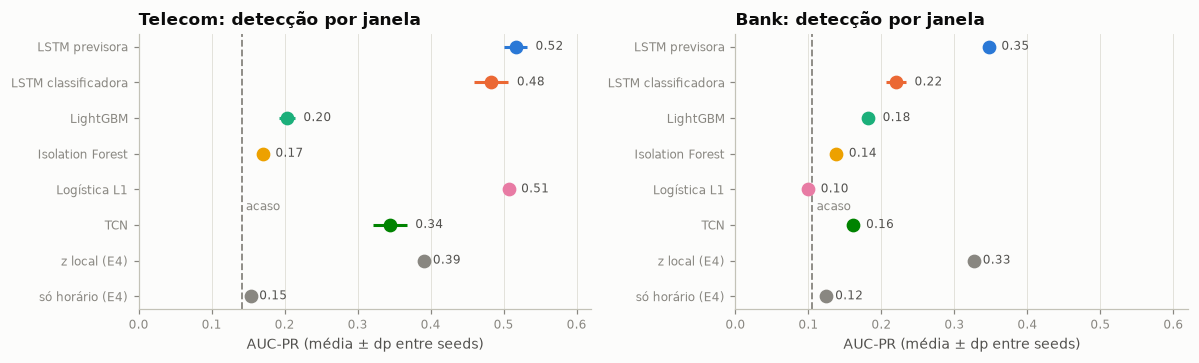

In [3]:
rows = []
for s in SYSTEMS:
    det = {**L[(s, "main")]["detection"], **A[(s, "main")]["detection"]}
    for key in MODELS:
        d = det[key]["summary"]
        rows.append(
            {
                "sistema": s,
                "modelo": MODELS[key][0],
                "AUC-PR": ms(d, "auc_pr"),
                "AUC-ROC": ms(d, "auc_roc"),
                "F1": ms(d, "f1"),
                "alarmes falsos/h": ms(d, "false_alarms_per_hour"),
            }
        )
    for e4_key in ("zscore_local", "lightgbm", "isolation_forest", "prior_horario"):
        e4 = B[(s, "main")]["detection"][e4_key]
        rows.append(
            {
                "sistema": s,
                "modelo": RIVAL_LABEL[e4_key],
                "AUC-PR": f"{e4['auc_pr']['value']:.2f}",
                "AUC-ROC": f"{e4['auc_roc']['value']:.2f}",
                "F1": f"{e4['f1']['value']:.2f}",
                "alarmes falsos/h": f"{e4['false_alarms_per_hour']['value']:.2f}",
            }
        )
display(pl.DataFrame(rows))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharex=True)
for ax, s in zip(axes, SYSTEMS, strict=True):
    det = {**L[(s, "main")]["detection"], **A[(s, "main")]["detection"]}
    for i, key in enumerate(MODELS):
        d = det[key]["summary"]["auc_pr"]
        label, color = MODELS[key]
        ax.errorbar(d["mean"], i, xerr=d["sd"], fmt="o", color=color, ms=8, elinewidth=2, capsize=0)
        ax.text(
            d["mean"] + max(d["sd"], 0.005) + 0.012,
            i,
            f"{d['mean']:.2f}",
            va="center",
            fontsize=8,
            color=INK2,
        )
    for j, e4_key in enumerate(("zscore_local", "prior_horario")):
        e4 = B[(s, "main")]["detection"][e4_key]["auc_pr"]["value"]
        y = len(MODELS) + j
        ax.plot(e4, y, "o", color=MUTED, ms=8)
        ax.text(e4 + 0.012, y, f"{e4:.2f}", va="center", fontsize=8, color=INK2)
    chance = next(iter(B[(s, "main")]["detection"].values()))["positive_rate"]
    ax.axvline(chance, color=MUTED, lw=1.2, ls="--")
    ax.text(chance + 0.006, len(MODELS) - 1.5, "acaso", fontsize=8, color=MUTED, va="center")
    clean_y(ax, [MODELS[k][0] for k in MODELS] + ["z local (E4)", "só horário (E4)"])
    ax.set_xlim(0, 0.62)
    ax.set_xlabel("AUC-PR (média ± dp entre seeds)")
    ax.set_title(f"{s}: detecção por janela", loc="left")
fig.tight_layout()
plt.show()

### Comparação pareada com as LSTMs e com os baselines da E4

Diferença de AUC-PR (modelo alternativo − referência) nas mesmas janelas de teste; contra as LSTMs, com a mesma seed. A tabela traz todas as referências; o gráfico mostra as três principais (as duas LSTMs e o z-score local). A contagem S / E / I diz em quantas seeds o IC da diferença ficou acima de 0 (superior), contém 0 (empate) ou abaixo (inferior).

sistema,modelo,contra,diferença média,IC médio,S / E / I
str,str,str,str,str,str
"""Telecom""","""LightGBM""","""LSTM previsora""","""-0.313""","""[-0.444, -0.149]""","""0 / 0 / 5"""
"""Telecom""","""LightGBM""","""LSTM classificadora""","""-0.279""","""[-0.403, -0.149]""","""0 / 0 / 5"""
"""Telecom""","""LightGBM""","""z 3 sigma (E4)""","""-0.035""","""[-0.164, +0.090]""","""0 / 5 / 0"""
"""Telecom""","""LightGBM""","""z local (E4)""","""-0.188""","""[-0.322, -0.040]""","""0 / 0 / 5"""
"""Telecom""","""LightGBM""","""Isolation Forest (E4)""","""+0.040""","""[-0.060, +0.168]""","""0 / 5 / 0"""
…,…,…,…,…,…
"""Bank""","""TCN""","""z 3 sigma (E4)""","""+0.061""","""[+0.014, +0.140]""","""5 / 0 / 0"""
"""Bank""","""TCN""","""z local (E4)""","""-0.166""","""[-0.236, -0.080]""","""0 / 0 / 5"""
"""Bank""","""TCN""","""Isolation Forest (E4)""","""+0.020""","""[-0.051, +0.103]""","""0 / 5 / 0"""


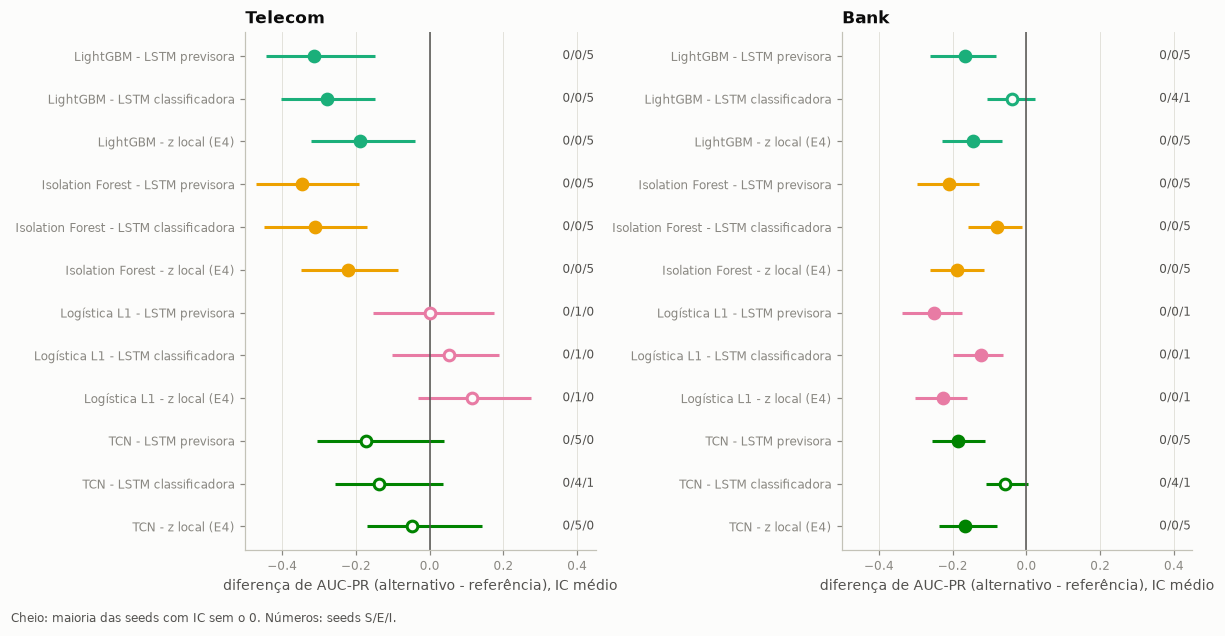

In [4]:
def paired_rows(key, task):
    out = []
    for s in SYSTEMS:
        for p in A[(s, key)]["paired"]:
            if p["task"] != task:
                continue
            out.append({"sistema": s, **p})
    return out


det_pairs = paired_rows("main", "detecção")
display(
    pl.DataFrame(
        [
            {
                "sistema": p["sistema"],
                "modelo": MODELS[p["model"]][0],
                "contra": RIVAL_LABEL[p["rival"]],
                "diferença média": f"{p['diff_mean']:+.3f}",
                "IC médio": f"[{p['ci_low_mean']:+.3f}, {p['ci_high_mean']:+.3f}]",
                "S / E / I": f"{p['superior']} / {p['empate']} / {p['inferior']}",
            }
            for p in det_pairs
        ]
    )
)

PLOT_RIVALS = ("lstm_forecast", "lstm_classifier", "zscore_local")
fig, axes = plt.subplots(1, 2, figsize=(11, 5.6), sharex=True)
for ax, s in zip(axes, SYSTEMS, strict=True):
    pairs = [p for p in det_pairs if p["sistema"] == s and p["rival"] in PLOT_RIVALS]
    labels = []
    for i, p in enumerate(pairs):
        color = MODELS[p["model"]][1]
        clear = p["superior"] + p["inferior"] > p["empate"]
        ax.errorbar(
            p["diff_mean"],
            i,
            xerr=[[p["diff_mean"] - p["ci_low_mean"]], [p["ci_high_mean"] - p["diff_mean"]]],
            fmt="o",
            ms=7,
            color=color,
            mfc=color if clear else SURFACE,
            mew=2,
            elinewidth=2,
            capsize=0,
        )
        ax.text(
            0.36,
            i,
            f"{p['superior']}/{p['empate']}/{p['inferior']}",
            va="center",
            fontsize=8,
            color=INK2,
        )
        labels.append(f"{MODELS[p['model']][0]} - {RIVAL_LABEL[p['rival']]}")
    ax.axvline(0, color=INK2, lw=1)
    clean_y(ax, labels)
    ax.set_xlim(-0.5, 0.45)
    ax.set_xlabel("diferença de AUC-PR (alternativo - referência), IC médio")
    ax.set_title(f"{s}", loc="left")
fig.text(
    0.01,
    -0.02,
    "Cheio: maioria das seeds com IC sem o 0. Números: seeds S/E/I.",
    fontsize=8,
    color=INK2,
)
fig.tight_layout()
plt.show()

**Leitura (detecção).**

- **Telecom:**
  - a **regressão logística L1 empata com as duas LSTMs e com o z-score local** (AUC-PR 0,51, contra 0,52 da previsora e 0,39 do z-score local) e supera os demais baselines;
  - a TCN (0,34) empata com a previsora, com o z-score local e, na maioria das seeds, com a classificadora;
  - LightGBM e Isolation Forest perdem para as duas LSTMs e para o z-score local, e não superam a referência só de horário.
- **Bank:**
  - nenhum alternativo é competitivo: todos perdem para a previsora LSTM (0,35) e para o z-score local (0,33) em todas as seeds;
  - a logística cai ao acaso (AUC-PR 0,10; a busca escolheu C = 0,1, contra 10 no Telecom);
  - só o LightGBM supera a referência só de horário, e só em 2 das 5 seeds.
- **Conclusão:** a **previsora LSTM** é o único candidato que fica entre os melhores nos dois sistemas. Ela não é necessária para detectar: no Telecom, a logística empata com ela; no Bank, o z-score local, sem aprendizado, empata.

## 2. Localização via XAI (RQ2)

Para cada falha testada, a explicação da janela-oráculo é somada por componente, e mede-se a posição do componente verdadeiro (HR@1 e MRR). Os valores das LSTMs vêm da E6 (mesmas falhas, mesma seed explicada); o nativo da E5 e as heurísticas da E4 aparecem em cinza. A tabela pareada inclui também a referência de frequência no treino da E4.

sistema,modelo,explicador,HR@1,HR@3,MRR
str,str,str,str,str,str
"""Telecom""","""LSTM previsora""","""SHAP""","""0.42 [0.29, 0.58]""","""0.78 [0.64, 0.89]""","""0.61 [0.50, 0.71]"""
"""Telecom""","""LSTM previsora""","""LIME""","""0.44 [0.31, 0.60]""","""0.76 [0.62, 0.87]""","""0.60 [0.49, 0.71]"""
"""Telecom""","""LSTM classificadora""","""SHAP""","""0.27 [0.13, 0.40]""","""0.51 [0.36, 0.64]""","""0.42 [0.32, 0.53]"""
"""Telecom""","""LSTM classificadora""","""LIME""","""0.13 [0.04, 0.22]""","""0.33 [0.20, 0.47]""","""0.29 [0.20, 0.39]"""
"""Telecom""","""LightGBM""","""SHAP""","""0.04 [0.00, 0.11]""","""0.24 [0.13, 0.38]""","""0.16 [0.11, 0.24]"""
…,…,…,…,…,…
"""Bank""","""Isolation Forest""","""LIME""","""0.03 [0.01, 0.07]""","""0.27 [0.19, 0.35]""","""0.22 [0.19, 0.26]"""
"""Bank""","""Logística L1""","""SHAP""","""0.15 [0.09, 0.21]""","""0.32 [0.23, 0.41]""","""0.30 [0.24, 0.36]"""
"""Bank""","""Logística L1""","""LIME""","""0.08 [0.03, 0.13]""","""0.25 [0.17, 0.33]""","""0.25 [0.20, 0.29]"""


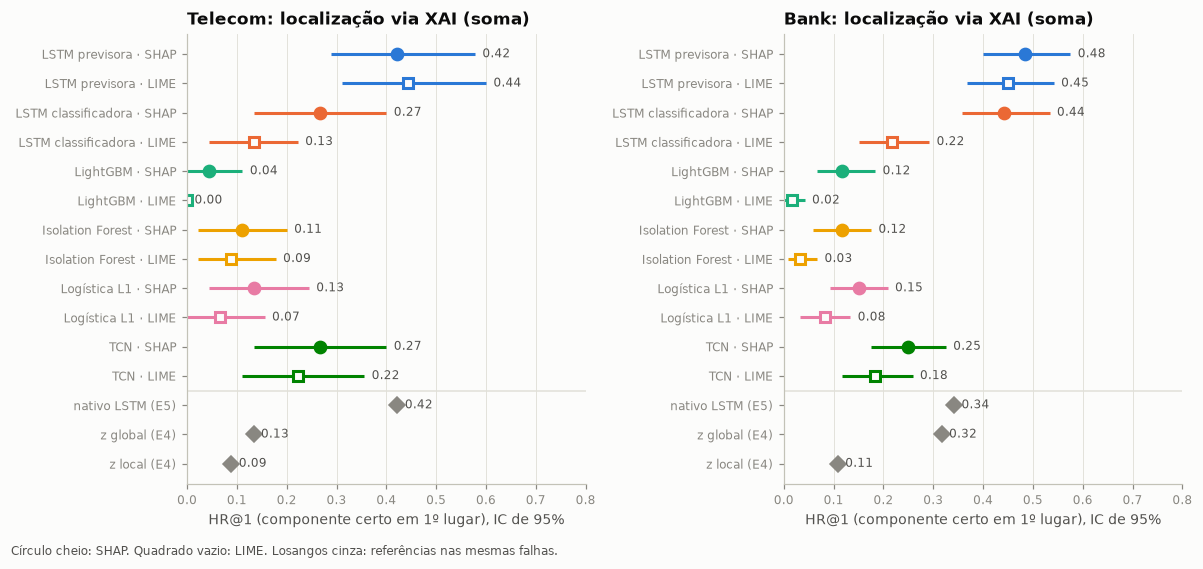

In [5]:
def ci(e):
    return f"{e['value']:.2f} [{e['ci_low']:.2f}, {e['ci_high']:.2f}]"


def loc_value(s, key, model, explainer):
    src = X[(s, key)]["localization"] if model in LSTM else A[(s, key)]["localization"]
    return src[f"{model}/{explainer}/sum"]


rows = []
for s in SYSTEMS:
    for model in MODELS:
        for explainer in ("shap", "lime"):
            e = loc_value(s, "main", model, explainer)
            rows.append(
                {
                    "sistema": s,
                    "modelo": MODELS[model][0],
                    "explicador": explainer.upper(),
                    "HR@1": ci(e["hr@1"]),
                    "HR@3": ci(e["hr@3"]),
                    "MRR": ci(e["mrr"]),
                }
            )
display(pl.DataFrame(rows))


def reference_hr1(s, key="main"):
    suffix = "" if key == "main" else "_sem_isencao"
    lstm_t = read_json(TABLES / f"lstm_{s}_lstm{suffix}.json")
    base_t = read_json(TABLES / f"baselines_{s}_baselines{suffix}.json")
    e5 = pl.read_csv(
        Path("experiments") / lstm_t["run_dir"] / "artifacts" / "localization_ranks.csv"
    )
    native = e5.filter((pl.col("method") == "lstm_sum") & (pl.col("seed") == 0))["rank"].to_numpy()
    return {
        "nativo LSTM (E5)": float(np.mean(native == 1)),
        "z global (E4)": base_t["localization"]["hr@1"]["value"],
        "z local (E4)": base_t["localization_local"]["hr@1"]["value"],
    }


fig, axes = plt.subplots(1, 2, figsize=(11, 5.0), sharex=True)
for ax, s in zip(axes, SYSTEMS, strict=True):
    labels, i = [], 0
    for model in MODELS:
        label, color = MODELS[model]
        for explainer, marker in (("shap", "o"), ("lime", "s")):
            e = loc_value(s, "main", model, explainer)["hr@1"]
            ax.errorbar(
                e["value"],
                i,
                xerr=[[e["value"] - e["ci_low"]], [e["ci_high"] - e["value"]]],
                fmt=marker,
                color=color,
                ms=7,
                elinewidth=2,
                capsize=0,
                mfc=color if explainer == "shap" else SURFACE,
                mew=2,
            )
            ax.text(
                e["ci_high"] + 0.015, i, f"{e['value']:.2f}", va="center", fontsize=8, color=INK2
            )
            labels.append(f"{label} · {explainer.upper()}")
            i += 1
    ax.axhline(i - 0.5, color=GRID, lw=1)
    for name, v in reference_hr1(s).items():
        ax.plot(v, i, "D", color=MUTED, ms=7)
        ax.text(v + 0.015, i, f"{v:.2f}", va="center", fontsize=8, color=INK2)
        labels.append(name)
        i += 1
    clean_y(ax, labels)
    ax.set_xlim(0, 0.8)
    ax.set_xlabel("HR@1 (componente certo em 1º lugar), IC de 95%")
    ax.set_title(f"{s}: localização via XAI (soma)", loc="left")
fig.text(
    0.01,
    -0.02,
    "Círculo cheio: SHAP. Quadrado vazio: LIME. Losangos cinza: referências nas mesmas falhas.",
    fontsize=8,
    color=INK2,
)
fig.tight_layout()
plt.show()

In [6]:
loc_pairs = [p for p in paired_rows("main", "localização") if p["metric"] == "hr@1"]
verdict = lambda p: "superior" if p["superior"] else ("inferior" if p["inferior"] else "empate")  # noqa: E731
grid = {}
for p in loc_pairs:
    model, explainer, _ = p["model"].split("/")
    rival = p["rival"].split("/")[0] if "/" in p["rival"] else p["rival"]
    grid.setdefault((p["sistema"], MODELS[model][0], explainer.upper()), {})[
        RIVAL_LABEL[rival] + (" (mesmo explicador)" if "/" in p["rival"] else "")
    ] = f"{p['diff_mean']:+.2f} {verdict(p)}"
display(
    pl.DataFrame(
        [{"sistema": k[0], "modelo": k[1], "explicador": k[2], **v} for k, v in grid.items()]
    )
)

sistema,modelo,explicador,LSTM previsora (mesmo explicador),LSTM classificadora (mesmo explicador),nativo LSTM (E5),frequência no treino (E4),z global (E4),z local (E4)
str,str,str,str,str,str,str,str,str
"""Telecom""","""LightGBM""","""SHAP""","""-0.38 inferior""","""-0.22 inferior""","""-0.38 inferior""","""-0.04 empate""","""-0.09 empate""","""-0.04 empate"""
"""Telecom""","""LightGBM""","""LIME""","""-0.44 inferior""","""-0.13 inferior""","""-0.42 inferior""","""-0.09 inferior""","""-0.13 inferior""","""-0.09 inferior"""
"""Telecom""","""Isolation Forest""","""SHAP""","""-0.31 inferior""","""-0.16 empate""","""-0.31 inferior""","""+0.02 empate""","""-0.02 empate""","""+0.02 empate"""
"""Telecom""","""Isolation Forest""","""LIME""","""-0.36 inferior""","""-0.04 empate""","""-0.33 inferior""","""+0.00 empate""","""-0.04 empate""","""+0.00 empate"""
"""Telecom""","""Logística L1""","""SHAP""","""-0.29 inferior""","""-0.13 empate""","""-0.29 inferior""","""+0.04 empate""","""+0.00 empate""","""+0.04 empate"""
…,…,…,…,…,…,…,…,…
"""Bank""","""Isolation Forest""","""LIME""","""-0.42 inferior""","""-0.18 inferior""","""-0.31 inferior""","""-0.07 inferior""","""-0.28 inferior""","""-0.07 inferior"""
"""Bank""","""Logística L1""","""SHAP""","""-0.33 inferior""","""-0.29 inferior""","""-0.19 inferior""","""+0.04 empate""","""-0.17 inferior""","""+0.04 empate"""
"""Bank""","""Logística L1""","""LIME""","""-0.37 inferior""","""-0.13 inferior""","""-0.26 inferior""","""-0.03 empate""","""-0.23 inferior""","""-0.03 empate"""


**Leitura (localização).**

- **Modelos tabulares (LightGBM, Isolation Forest, logística):** localizam mal nos dois sistemas, com HR@1 entre 0,00 e 0,15.
  - São **inferiores à XAI da LSTM previsora e ao ranqueamento nativo em todas as comparações de HR@1**, nos dois sistemas.
  - No Telecom empatam com as heurísticas da E4, exceto o LIME do LightGBM, que perde até para elas. No Bank são inferiores ao z-score global e, no máximo, empatam com a referência de frequência no treino, que não lê telemetria.

  O motivo provável: as estatísticas da janela (média, desvio, mín., máx., último) diluem o desvio de cada KPI, e os modelos separam as classes com poucos atributos, sem relação com o componente da falha. Um bom detector não precisa olhar para o componente certo.
- **TCN:** localiza melhor que os tabulares, mas abaixo da previsora LSTM.
  - **Telecom:** HR@1 0,27 com SHAP; empata com a XAI das duas LSTMs e com o nativo, e é superior ao z local e à referência de frequência. Com LIME (0,22) perde para a previsora e para o nativo.
  - **Bank:** HR@1 0,25 com SHAP; perde para o SHAP das duas LSTMs (0,48 e 0,44), empata com o nativo e é superior ao z local. O LIME da TCN fica abaixo da previsora, do nativo e do z global.

  A estrutura sequencial da entrada (janela × KPI) parece importar mais para localizar do que a recorrência.
- **Conclusão:** para **localizar** com XAI, os modelos sequenciais (LSTM e TCN) são claramente melhores que os tabulares. A **XAI da previsora LSTM** é a melhor localização medida nos dois sistemas (HR@1 0,42–0,44 no Telecom, 0,48 no Bank).

## 3. Qualidade das explicações

Mesmas medidas da E6, por janela-oráculo:

- **deleção:** pontuação ao retirar os k atributos mais importantes, relativa à original (menor = mais fiel), comparada a ordens aleatórias;
- **estabilidade:** Jaccard dos 10 atributos mais importantes entre a seed 0 e as seeds 1–4 (a logística é determinística) e entre janelas vizinhas (±1 min);
- **concordância:** Jaccard SHAP × LIME nos 10 mais importantes.

A inserção é mostrada pela **mediana**, porque é relativa à pontuação da janela completa: quando ela é quase 0 (probabilidade baixa numa janela de falha), a razão explode e a média perde sentido (Bank: médias de 10⁵).

sistema,modelo,deleção SHAP,deleção LIME,deleção aleatória,inserção SHAP (mediana),inserção aleatória (mediana),seeds (Jaccard),vizinhas (Jaccard),SHAP vs. LIME (Jaccard)
str,str,str,str,str,str,str,str,str,str
"""Telecom""","""LSTM previsora""","""0.54""","""0.53""","""0.99""","""0.70""","""0.03""","""0.85""","""0.75""","""0.73"""
"""Telecom""","""LSTM classificadora""","""0.76""","""0.76""","""1.00""","""0.77""","""0.29""","""0.20""","""0.45""","""0.45"""
"""Telecom""","""LightGBM""","""0.28""","""0.32""","""0.99""","""1.13""","""0.00""","""0.62""","""0.77""","""0.25"""
"""Telecom""","""Isolation Forest""","""0.97""","""0.97""","""1.00""","""0.94""","""0.92""","""0.03""","""0.67""","""0.37"""
"""Telecom""","""Logística L1""","""0.32""","""0.31""","""1.04""","""0.94""","""0.53""","""—""","""0.81""","""0.52"""
…,…,…,…,…,…,…,…,…,…
"""Bank""","""LSTM classificadora""","""0.70""","""0.71""","""1.00""","""1.45""","""1.00""","""0.26""","""0.54""","""0.48"""
"""Bank""","""LightGBM""","""0.37""","""0.28""","""1.01""","""2.93""","""0.04""","""0.59""","""0.86""","""0.20"""
"""Bank""","""Isolation Forest""","""0.97""","""0.97""","""1.00""","""0.80""","""0.77""","""0.03""","""0.73""","""0.38"""


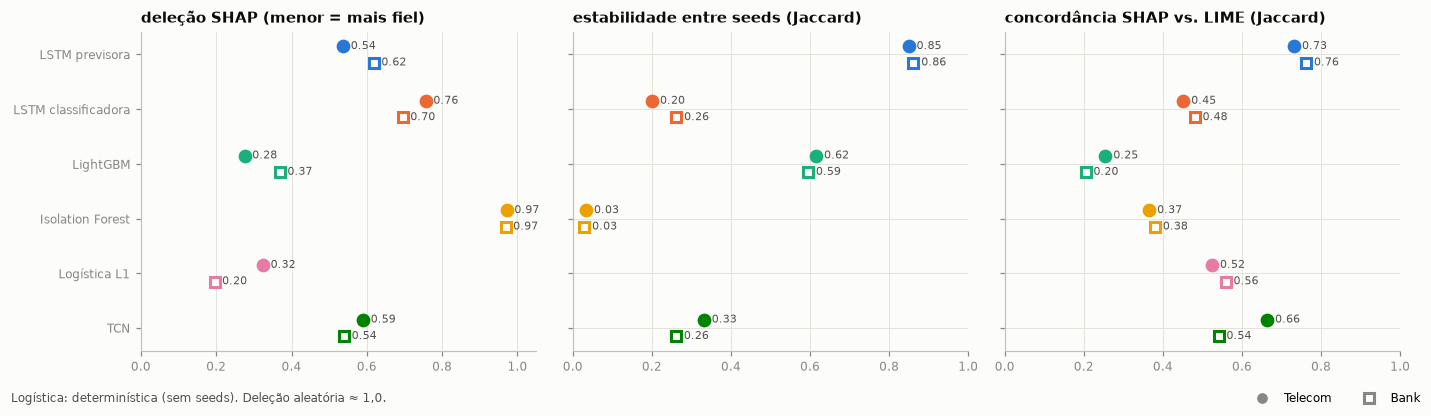

In [7]:
def quality_medians(path):
    q = pl.read_csv(path, infer_schema_length=None).filter(pl.col("deletion_shap").is_not_null())
    return {
        r["model"]: r
        for r in q.group_by("model")
        .agg(pl.col("insertion_shap").median(), pl.col("insertion_random").median())
        .iter_rows(named=True)
    }


rows = []
for s in SYSTEMS:
    med = {}
    for d in (
        X[(s, "main")]["run_dir"],
        A[(s, "main")]["run_dirs"]["tabular"],
        A[(s, "main")]["run_dirs"]["tcn"],
    ):
        med.update(quality_medians(Path("experiments") / d / "artifacts" / "xai_quality.csv"))
    quality = {**X[(s, "main")]["quality"], **A[(s, "main")]["quality"]}
    for model in MODELS:
        q = quality[model]
        f = lambda v: "—" if v is None else f"{v:.2f}"  # noqa: E731
        rows.append(
            {
                "sistema": s,
                "modelo": MODELS[model][0],
                "deleção SHAP": f(q["deletion_shap"]),
                "deleção LIME": f(q["deletion_lime"]),
                "deleção aleatória": f(q["deletion_random"]),
                "inserção SHAP (mediana)": f(med[model]["insertion_shap"]),
                "inserção aleatória (mediana)": f(med[model]["insertion_random"]),
                "seeds (Jaccard)": f(q["seed_jaccard"]),
                "vizinhas (Jaccard)": f(q["neighbour_jaccard"]),
                "SHAP vs. LIME (Jaccard)": f(q["shap_lime_jaccard"]),
            }
        )
QUALITY = pl.DataFrame(rows)
display(QUALITY)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
measures = (
    ("deletion_shap", "deleção SHAP (menor = mais fiel)", (0, 1.05)),
    ("seed_jaccard", "estabilidade entre seeds (Jaccard)", (0, 1.0)),
    ("shap_lime_jaccard", "concordância SHAP vs. LIME (Jaccard)", (0, 1.0)),
)
for ax, (key, title, xlim) in zip(axes, measures, strict=True):
    for i, model in enumerate(MODELS):
        label, color = MODELS[model]
        for k, (s, marker) in enumerate((("Telecom", "o"), ("Bank", "s"))):
            quality = {**X[(s, "main")]["quality"], **A[(s, "main")]["quality"]}
            v = quality[model][key]
            if v is None:
                continue
            y = i + (k - 0.5) * 0.3
            ax.plot(
                v, y, marker, color=color, ms=7, mfc=color if s == "Telecom" else SURFACE, mew=2
            )
            ax.text(v + 0.02, y, f"{v:.2f}", va="center", fontsize=7, color=INK2)
    ax.set_xlim(*xlim)
    ax.set_title(title, loc="left", fontsize=10)
clean_y(axes[0], [MODELS[m][0] for m in MODELS])
handles = [
    plt.Line2D([], [], marker="o", ls="", color=MUTED, label="Telecom"),
    plt.Line2D([], [], marker="s", ls="", color=MUTED, mfc=SURFACE, mew=2, label="Bank"),
]
fig.legend(handles=handles, loc="lower right", ncol=2)
fig.text(
    0.01,
    -0.03,
    "Logística: determinística (sem seeds). Deleção aleatória ≈ 1,0.",
    fontsize=8,
    color=INK2,
)
fig.tight_layout()
plt.show()

**Leitura (qualidade).**

- **Fidelidade:** as explicações de LightGBM, logística e TCN são **mais fiéis** que as da LSTM: retirando os atributos apontados, a pontuação cai para 20%–37% da original no LightGBM e na logística e para 54%–60% na TCN, contra 54%–76% nas LSTMs (aleatório ≈ 100%). Modelos tabulares dependem de poucos atributos, e SHAP exato os encontra. Fidelidade alta, porém, não implicou localizar o componente certo (seção 2).
- **Isolation Forest:** explicações **quase sem fidelidade** (deleção 0,97, aleatório 1,00) e **instáveis entre seeds** (Jaccard 0,03): florestas de isolamento com sementes diferentes isolam a janela por atributos diferentes, e nenhum atributo isolado move muito a pontuação.
- **Estabilidade entre seeds:** LightGBM 0,59–0,62, TCN 0,26–0,33, LSTM previsora 0,85–0,86 e classificadora 0,20–0,26. A previsora LSTM continua com as explicações mais estáveis, o que reforça a escolha da E6 para os pacotes do agente.
- **SHAP × LIME:** a concordância segue a regra da E6: maior quando o modelo é simples ou suave (logística 0,52–0,56, TCN 0,54–0,66, previsora 0,73–0,76) e menor nas árvores (LightGBM 0,20–0,25).

## 4. Sensibilidade à isenção de disponibilidade

O controle sem isenção repete os modelos sem os KPIs de disponibilidade (ameaça nº 1), reaproveitando a seleção da execução principal, e compara com as LSTMs também sem isenção.

In [8]:
rows = []
for s in SYSTEMS:
    for model in MODELS:
        det = {k: {**L[(s, k)]["detection"], **A[(s, k)]["detection"]} for k in ("main", "sem")}
        row = {"sistema": s, "modelo": MODELS[model][0]}
        for k, name in (("main", "com"), ("sem", "sem")):
            row[f"AUC-PR {name}"] = f"{det[k][model]['summary']['auc_pr']['mean']:.2f}"
            row[f"HR@1 SHAP {name}"] = f"{loc_value(s, k, model, 'shap')['hr@1']['value']:.2f}"
        rows.append(row)
display(pl.DataFrame(rows))

changed = []
for s in SYSTEMS:
    main = {(p["task"], p["model"], p["rival"], p["metric"]): p for p in A[(s, "main")]["paired"]}
    for p in A[(s, "sem")]["paired"]:
        m = main[(p["task"], p["model"], p["rival"], p["metric"])]
        if (p["superior"], p["empate"], p["inferior"]) != (
            m["superior"],
            m["empate"],
            m["inferior"],
        ) and p["metric"] in ("auc_pr", "hr@1"):
            changed.append(
                {
                    "sistema": s,
                    "tarefa": p["task"],
                    "modelo": p["model"],
                    "contra": p["rival"],
                    "com isenção (S/E/I)": f"{m['superior']}/{m['empate']}/{m['inferior']}",
                    "sem isenção (S/E/I)": f"{p['superior']}/{p['empate']}/{p['inferior']}",
                }
            )
print(f"comparações cujo veredito muda sem a isenção: {len(changed)}")
display(pl.DataFrame(changed))

sistema,modelo,AUC-PR com,HR@1 SHAP com,AUC-PR sem,HR@1 SHAP sem
str,str,str,str,str,str
"""Telecom""","""LSTM previsora""","""0.52""","""0.42""","""0.43""","""0.24"""
"""Telecom""","""LSTM classificadora""","""0.48""","""0.27""","""0.49""","""0.22"""
"""Telecom""","""LightGBM""","""0.20""","""0.04""","""0.21""","""0.04"""
"""Telecom""","""Isolation Forest""","""0.17""","""0.11""","""0.17""","""0.18"""
"""Telecom""","""Logística L1""","""0.51""","""0.13""","""0.50""","""0.09"""
…,…,…,…,…,…
"""Bank""","""LSTM classificadora""","""0.22""","""0.44""","""0.21""","""0.43"""
"""Bank""","""LightGBM""","""0.18""","""0.12""","""0.18""","""0.12"""
"""Bank""","""Isolation Forest""","""0.14""","""0.12""","""0.14""","""0.09"""


comparações cujo veredito muda sem a isenção: 28


sistema,tarefa,modelo,contra,com isenção (S/E/I),sem isenção (S/E/I)
str,str,str,str,str,str
"""Telecom""","""detecção""","""lightgbm""","""lightgbm""","""0/1/4""","""0/0/5"""
"""Telecom""","""detecção""","""isolation_forest""","""zscore_3sigma""","""0/0/5""","""0/1/4"""
"""Telecom""","""localização""","""lightgbm/lime/sum""","""lstm_classifier/lime""","""0/0/1""","""0/1/0"""
"""Telecom""","""localização""","""lightgbm/lime/sum""","""prior""","""0/0/1""","""0/1/0"""
"""Telecom""","""localização""","""lightgbm/lime/sum""","""zscore_global""","""0/0/1""","""0/1/0"""
…,…,…,…,…,…
"""Bank""","""detecção""","""tcn""","""prior_horario""","""0/5/0""","""1/4/0"""
"""Bank""","""localização""","""tcn/lime/sum""","""lstm_nativo_soma""","""0/0/1""","""0/1/0"""
"""Bank""","""localização""","""tcn/lime/sum""","""prior""","""0/1/0""","""1/0/0"""


**Leitura.** Os números dos modelos alternativos quase não mudam sem a isenção (tabela acima). Nenhum veredito de detecção muda; os de localização mudam em dois lugares:

- **Telecom:** 20 comparações passam de "inferior" a "empate" (2 de "superior" a "empate" e 2 no sentido contrário). Quem muda é a referência: sem os KPIs de disponibilidade, a localização da LSTM cai (E5/E6), e a distância para os alternativos diminui.
- **Bank:** os modelos tabulares não mudam. A TCN muda (HR@1 com SHAP de 0,25 para 0,33), porque é retreinada sem esses KPIs; a diferença é da ordem da variação entre seeds. São 5 comparações de "inferior" para "empate" e 3 de "empate" para "superior".

**Consequência para as conclusões:**
- **Bank:** as conclusões das seções 1 e 2 valem sem a isenção.
- **Telecom:** sem a isenção, parte da vantagem da LSTM sobre os tabulares na localização vira empate, como acontece com a vantagem da LSTM sobre as heurísticas na E6 (ameaça nº 1). Os tabulares continuam com HR@1 baixo (0,02 a 0,18); o que cai é a LSTM.

## 5. Busca e custo

Configuração escolhida na validação (8 por modelo) e custo em CPU (Apple M4 Pro). A busca completa, com a AUC-PR de validação de cada configuração, está em `reports/tables/alt_models_<sistema>_alt_*.md`.

In [9]:
rows = []
for s in SYSTEMS:
    a = A[(s, "main")]
    for model in ALT:
        sel, cost = a["selection"][model], a["cost"][model]
        rows.append(
            {
                "sistema": s,
                "modelo": MODELS[model][0],
                "normalização": sel["normalization"],
                "hiperparâmetros": json.dumps(sel["params"]),
                "treino por modelo (s)": cost["train_seconds_mean"],
                "inferência (ms/janela)": cost["inference_ms_per_window"],
                "XAI por janela (s)": cost["xai_seconds_per_window"],
            }
        )
display(pl.DataFrame(rows))

sistema,modelo,normalização,hiperparâmetros,treino por modelo (s),inferência (ms/janela),XAI por janela (s)
str,str,str,str,f64,f64,f64
"""Telecom""","""LightGBM""","""global""","""{""n_estimators"": 600, ""num_lea…",8.19,0.0226,0.88
"""Telecom""","""Isolation Forest""","""global""","""{""max_samples"": 1024, ""n_estim…",0.14,0.0264,3.79
"""Telecom""","""Logística L1""","""global""","""{""c"": 10.0}""",0.2,0.0057,0.44
"""Telecom""","""TCN""","""local""","""{""blocks"": 2, ""channels"": 32}""",8.17,0.4766,2.89
"""Bank""","""LightGBM""","""local""","""{""n_estimators"": 600, ""num_lea…",17.49,0.0221,0.73
"""Bank""","""Isolation Forest""","""global""","""{""max_samples"": 256, ""n_estima…",0.33,0.0123,1.37
"""Bank""","""Logística L1""","""global""","""{""c"": 0.1}""",1.11,0.0033,0.36
"""Bank""","""TCN""","""local""","""{""blocks"": 3, ""channels"": 32}""",24.18,0.4844,2.98


## Conclusões

1. **Detecção (RQ1):** a **previsora LSTM** é o único candidato entre os melhores nos dois sistemas, mas não é necessária. No Telecom, a **regressão logística L1** e a classificadora LSTM empatam com ela; no Bank, o **z-score local da E4**, sem aprendizado, empata. Nenhum alternativo é competitivo no Bank, e LightGBM e Isolation Forest não superam nem a referência só de horário no Telecom.
2. **Localização via XAI (RQ2):** os modelos **tabulares localizam mal** (HR@1 ≤ 0,15). São inferiores à XAI da previsora LSTM e ao ranqueamento nativo em todas as comparações, e no Bank até ao z-score global. A **TCN fica entre os tabulares e a LSTM**: empata no Telecom com SHAP e perde no Bank. A XAI da previsora LSTM é a melhor localização medida nos dois sistemas.
3. **Qualidade:** explicações de modelos tabulares são mais fiéis (dependem de poucos atributos), mas isso não as torna úteis para localizar; as do Isolation Forest não são fiéis nem estáveis. A **previsora LSTM tem as explicações mais estáveis** entre seeds.
4. **Para o agente (E7):** nada muda. Os pacotes continuam vindo da LSTM, como decidido antes deste teste (ameaça nº 19); o resultado reforça a escolha, já que nenhum alternativo localiza melhor.